# Digital Model of a Sucker Rod Pump (Stage 1)

This notebook follows the methodology in our literature review, step by step:

| Step | What happens |
|---|---|
| 0 | Input data (pumping unit, well, rods) |
| 2 | Polished rod motion: simple harmonic model vs exact four-bar linkage model |
| 3 | Rod loads: weight in air, buoyant weight, fluid load, rod stretch |
| 4 | Ideal dynamometer card |
| 5 | "What if" cases: pumping speed, stroke length, pump filling |
| ✓ | Checks against the handbook (Takács, 2015) |

(Step 1, studying the basics, is the literature review itself.)

**How to run:** *Runtime → Run all* in Google Colab, or *Run → Run All Cells* in Jupyter.
Nothing needs installing in Colab. In Jupyter you need `numpy` and `matplotlib`.

**To try your own numbers:** change the values in the **Step 0** cell, then run all cells again.

Units are the handbook's oilfield units: inches, feet, pounds (lb), strokes per minute (SPM).

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("outputs")          # graphs and data are also saved here
OUT.mkdir(exist_ok=True)

# ---- one consistent look for every graph ----
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
BLUE_RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]   # light -> dark
plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelcolor": INK, "axes.edgecolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "lines.linewidth": 2.0,
})


def _ramp(n):
    """Pick n shades of blue, light to dark, for ordered cases."""
    return BLUE_RAMP[-n:] if n <= len(BLUE_RAMP) else plt.cm.Blues(np.linspace(0.4, 1, n))


def _klb(ax):
    """Show loads in thousands of pounds on the y-axis."""
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v/1000:g}"))


## Step 0 – Input data

All the numbers come from worked examples in the handbook, so we can check our answers against the book:

- **Pumping unit:** C-228D-213-86 conventional unit, clockwise, 10 SPM (Example 3.17)
- **Well and rods:** pump at 5,000 ft, 2.5 in plunger, 3/4 in + 5/8 in rods (Example 3.10)
- **Rod properties:** Table 3.9

In [2]:
# ----------------------------------------------------------------------
# 1. PUMPING UNIT (conventional, crank-balanced)  -  review section 2.5
# ----------------------------------------------------------------------
# API letters for the linkage dimensions (see handbook Fig. 3.99):
#   A = saddle (centre) bearing to the horsehead face
#   C = saddle bearing to the equalizer bearing
#   I = horizontal distance from the saddle bearing to the crankshaft
#   K = straight-line distance from the saddle bearing to the crankshaft
#   P = pitman length
#   R = crank radius (depends on which crank hole is used)
UNIT = {
    "name": "C-228D-213-86",
    "A": 111.0,     # in
    "C": 96.0,      # in
    "I": 96.0,      # in
    "K": 151.34,    # in
    "P": 114.0,     # in
    "R": 37.0,      # in
    "rotation": "CW",   # clockwise, seen with the wellhead on the right
    # From the name C-228D-213-86 (review section 2.5):
    "gearbox_rating_inlb": 228_000,   # 228 -> 228,000 in-lb peak torque
    "max_load_lb": 21_300,            # 213 -> 21,300 lb maximum polished rod load
    "max_stroke_in": 86,              # 86  -> 86 in maximum (nameplate) stroke
}

PUMPING_SPEED_SPM = 10.0   # N, strokes per minute

# ----------------------------------------------------------------------
# 2. WELL AND PUMP  -  review section 2.8
# ----------------------------------------------------------------------
PUMP_DEPTH_FT = 5000.0       # L, pump setting depth
PLUNGER_DIAMETER_IN = 2.5    # d
LIQUID_SPGR = 1.0            # specific gravity; 1.0 = water (handbook design assumption)

# ----------------------------------------------------------------------
# 3. ROD STRING  -  review section 2.3
# ----------------------------------------------------------------------
# Listed from the TOP of the well to the BOTTOM.
# Taper lengths are the ones worked out in handbook Example 3.10.
ROD_STRING = [
    {"size": "3/4", "length_ft": 3379.0},
    {"size": "5/8", "length_ft": 1621.0},
]

# Handbook Table 3.9 - Calculated Physical Data of API Sucker Rods
#   area_sqin       : metal area of the rod body (sq in)
#   weight_lb_ft    : average weight in air, including couplings (lb/ft)
#   elastic_in_lbft : elastic constant Er = stretch (in) of 1 ft of rod under 1 lb
ROD_TABLE = {
    "5/8":   {"area_sqin": 0.307, "weight_lb_ft": 1.135, "elastic_in_lbft": 1.262e-6},
    "3/4":   {"area_sqin": 0.442, "weight_lb_ft": 1.634, "elastic_in_lbft": 8.762e-7},
    "7/8":   {"area_sqin": 0.601, "weight_lb_ft": 2.224, "elastic_in_lbft": 6.437e-7},
    "1":     {"area_sqin": 0.785, "weight_lb_ft": 2.904, "elastic_in_lbft": 4.929e-7},
    "1 1/8": {"area_sqin": 0.994, "weight_lb_ft": 3.676, "elastic_in_lbft": 3.894e-7},
    "1 1/4": {"area_sqin": 1.227, "weight_lb_ft": 4.538, "elastic_in_lbft": 3.154e-7},
}

# ----------------------------------------------------------------------
# 4. "WHAT IF" CASES  -  review methodology step 5
# ----------------------------------------------------------------------
WHAT_IF_SPEEDS_SPM = [6.0, 8.0, 10.0, 12.0]
# Different crank holes give different stroke lengths. These radii are
# example crank-hole positions for illustration, not catalogue values.
WHAT_IF_CRANK_RADII_IN = [37.0, 32.0, 27.0]
WHAT_IF_PUMP_FILLAGE = [1.00, 0.75, 0.50]   # fraction of the barrel filled with liquid

# ----------------------------------------------------------------------
# Constants
# ----------------------------------------------------------------------
G_IN_S2 = 386.09      # acceleration of gravity, in/s^2
G_FT_S2 = 32.174      # acceleration of gravity, ft/s^2


The handbook's own results for this pumping unit (Exhibit 3.7) are stored below so we can compare against them later.
Columns: crank angle (deg), position of rods (fraction of stroke), torque factor (in), velocity (in/s), acceleration (in/s²).

In [3]:
# Handbook Exhibit 3.7 (C-228D-213-86, clockwise, 10 SPM)
# columns: crank angle (deg), position of rods PR (fraction of stroke),
#          torque factor (in), velocity (in/s), acceleration (in/s^2)
EXHIBIT_3_7 = np.array([
    [0, 0.001, -2.4, -2.5, 64.5], [15, 0.017, 13.4, 14.1, 66.5],
    [30, 0.079, 28.4, 29.7, 56.4], [45, 0.181, 39.5, 41.3, 35.3],
    [60, 0.308, 45.0, 47.1, 10.8], [75, 0.442, 45.1, 47.2, -8.4],
    [90, 0.571, 41.6, 43.6, -19.4], [105, 0.687, 36.3, 38.1, -23.9],
    [120, 0.786, 30.4, 31.9, -25.2], [135, 0.867, 24.4, 25.5, -25.6],
    [150, 0.931, 18.2, 19.0, -26.8], [165, 0.975, 11.4, 12.0, -29.8],
    [180, 0.997, 3.8, 4.0, -34.6], [195, 0.996, -5.2, -5.4, -40.3],
    [210, 0.966, -15.3, -16.0, -43.8], [225, 0.905, -25.6, -26.8, -41.6],
    [240, 0.815, -34.6, -36.3, -33.0], [255, 0.702, -41.1, -43.0, -20.7],
    [270, 0.575, -44.5, -46.6, -7.8], [285, 0.442, -44.8, -46.9, 4.7],
    [300, 0.312, -42.3, -44.3, 16.8], [315, 0.194, -36.8, -38.5, 29.1],
    [330, 0.097, -28.3, -29.6, 42.1], [345, 0.029, -16.7, -17.5, 54.7],
])
EXHIBIT_STROKE_IN = 88.35
EXHIBIT_UP_START_DEG, EXHIBIT_DOWN_START_DEG, EXHIBIT_UPSTROKE_DEG = 2.3, 186.6, 184.3


def handbook_table():
    """Exhibit 3.7 in the same units we plot (position in inches)."""
    return {
        "crank_deg": EXHIBIT_3_7[:, 0],
        "position_in": EXHIBIT_3_7[:, 1] * EXHIBIT_STROKE_IN,
        "velocity_in_s": EXHIBIT_3_7[:, 3],
        "accel_in_s2": EXHIBIT_3_7[:, 4],
    }


## Step 2 – Polished rod motion

**Simple harmonic model** (review section 2.6): the rod moves like a point on a turning circle,

$$s(\theta) = \frac{S}{2}(1-\cos\theta) \qquad\qquad |a_{max}| = \frac{S\,N^2}{2189}$$

where $a_{max}$ is in ft/s², $S$ in inches and $N$ in SPM.

**Exact four-bar linkage model** (review section 2.5): for every crank angle we find where the crank pin,
pitman and beam really are, using geometry. The beam angle gives the polished rod position. Velocity and
acceleration then come from numerical differentiation.

Crank angle 0° means the crank points straight up. The unit is viewed with the wellhead on the right.

In [4]:
def shm_motion(stroke_in, spm, theta_rad):
    """Simple harmonic model of the polished rod (handbook Eqs 3.48-3.51).

    stroke_in : stroke length S (in)
    spm       : pumping speed N (strokes per minute)
    theta_rad : array of crank angles (radians)

    Returns position (in), velocity (in/s) and acceleration (in/s^2).
    """
    omega = 2.0 * np.pi * spm / 60.0          # crank angular speed, rad/s
    position = stroke_in / 2.0 * (1.0 - np.cos(theta_rad))
    velocity = stroke_in / 2.0 * omega * np.sin(theta_rad)
    acceleration = stroke_in / 2.0 * omega**2 * np.cos(theta_rad)
    return {"position": position, "velocity": velocity, "acceleration": acceleration}


def mills_peak_acceleration_ft_s2(stroke_in, spm):
    """Peak acceleration from the simple model, Mills' formula (review 2.6):
           a_max = S * N^2 / 2189     (S in inches, answer in ft/s^2)
    """
    return stroke_in * spm**2 / 2189.0


def check_unit_geometry(unit):
    """Stop with a clear message if the dimensions cannot form a working
    pumping unit (for example, a typing mistake in the Step 0 input cell)."""
    K, C, P, R = unit["K"], unit["C"], unit["P"], unit["R"]
    if unit["I"] >= K:
        raise ValueError("I must be smaller than K. Check the Step 0 input cell.")
    # The distance from the saddle bearing to the crank pin swings between
    # K - R and K + R. The beam (C) and pitman (P) must be able to reach it.
    if not (K + R <= C + P and K - R >= abs(C - P)):
        raise ValueError("These dimensions cannot make a full crank turn. "
                         "Check A, C, I, K, P, R in the Step 0 input cell.")


def linkage_positions(unit, theta_rad):
    """Find where the joints of the linkage are for each crank angle.

    Coordinates (inches): origin at the saddle bearing O, x pointing
    towards the well, y pointing up.

    Returns crank pin (cx, cy), equalizer bearing (ex, ey) and the angle
    of the front (horsehead) arm of the beam above horizontal (rad).
    """
    A, C, I, K, P, R = (unit[k] for k in ("A", "C", "I", "K", "P", "R"))
    height_O_above_Q = np.sqrt(K**2 - I**2)       # vertical distance O to crankshaft
    qx, qy = -I, -height_O_above_Q                # crankshaft centre Q

    # Crank pin: moves on a circle of radius R around Q
    turn = 1.0 if unit["rotation"].upper() == "CW" else -1.0
    cx = qx + turn * R * np.sin(theta_rad)
    cy = qy + R * np.cos(theta_rad)

    # Equalizer bearing E: it is C away from O (beam is rigid) AND P away
    # from the crank pin (pitman is rigid). So E sits where a circle of
    # radius C around O crosses a circle of radius P around the crank pin.
    d = np.hypot(cx, cy)                          # distance O to crank pin
    a = (C**2 - P**2 + d**2) / (2.0 * d)
    h = np.sqrt(C**2 - a**2)
    ux, uy = cx / d, cy / d                       # unit vector O -> crank pin
    e1x, e1y = a * ux - h * uy, a * uy + h * ux   # the two crossing points
    e2x, e2y = a * ux + h * uy, a * uy - h * ux
    upper = e1y > e2y                             # the real one is the upper one
    ex = np.where(upper, e1x, e2x)
    ey = np.where(upper, e1y, e2y)

    # The horsehead arm points the opposite way from O->E
    beam_angle = np.arctan2(-ey, -ex)
    return cx, cy, ex, ey, beam_angle


def exact_motion(unit, spm, n_points=3600):
    """Exact polished rod motion over one crank turn.

    n_points = 3600 gives one point every 0.1 degree of crank angle.
    Velocity and acceleration are found by numerical differentiation
    (central differences), which is very accurate at this spacing.
    """
    check_unit_geometry(unit)
    theta = np.linspace(0.0, 2.0 * np.pi, n_points, endpoint=False)
    dtheta = theta[1] - theta[0]
    omega = 2.0 * np.pi * spm / 60.0

    cx, cy, ex, ey, beam_angle = linkage_positions(unit, theta)

    # The horsehead face is an arc of radius A around O, so the polished
    # rod moves by A x (change in beam angle). Measure from the bottom.
    position = unit["A"] * (beam_angle - beam_angle.min())

    # d(position)/d(theta) is the TORQUE FACTOR (in) - handbook Eq. 3.63
    nxt, prv = np.roll(position, -1), np.roll(position, 1)
    torque_factor = (nxt - prv) / (2.0 * dtheta)
    d2x_dtheta2 = (nxt - 2.0 * position + prv) / dtheta**2

    velocity = torque_factor * omega              # in/s   (handbook Eq. 3.60)
    acceleration = d2x_dtheta2 * omega**2         # in/s^2 (constant crank speed)

    i_bottom, i_top = int(np.argmin(position)), int(np.argmax(position))
    theta_deg = np.degrees(theta)
    upstroke_deg = (theta_deg[i_top] - theta_deg[i_bottom]) % 360.0

    return {
        "theta_rad": theta, "theta_deg": theta_deg, "spm": spm, "omega": omega,
        "position": position, "velocity": velocity, "acceleration": acceleration,
        "torque_factor": torque_factor,
        "stroke": float(position.max()),
        "i_bottom": i_bottom, "i_top": i_top,
        "bottom_deg": float(theta_deg[i_bottom]), "top_deg": float(theta_deg[i_top]),
        "upstroke_deg": float(upstroke_deg), "downstroke_deg": float(360.0 - upstroke_deg),
        "joints": (cx, cy, ex, ey, beam_angle),
    }


def exact_stroke_formula(unit):
    """Stroke length straight from the handbook formula (Eqs 3.57-3.58),
    used as an independent check on the numerical result:
        S = A * (psi_bottom - psi_top)
    where the angles come from the two 'dead centre' positions, when the
    crank and pitman lie in one straight line.
    """
    A, C, K, P, R = unit["A"], unit["C"], unit["K"], unit["P"], unit["R"]
    psi_bottom = np.arccos((K**2 + C**2 - (P + R)**2) / (2.0 * K * C))
    psi_top = np.arccos((K**2 + C**2 - (P - R)**2) / (2.0 * K * C))
    return float(A * (psi_bottom - psi_top))


In [5]:
unit, N = UNIT, PUMPING_SPEED_SPM
exact = exact_motion(unit, N)
shm = shm_motion(exact["stroke"], N, exact["theta_rad"])
S = exact["stroke"]
mills = mills_peak_acceleration_ft_s2(S, N)

print(f"Stroke length S                     : {S:7.2f} in  ({S*0.0254:.2f} m)")
print(f"Upstroke / downstroke (crank angle) : {exact['upstroke_deg']:.1f} / {exact['downstroke_deg']:.1f} deg   (simple model: 180 / 180)")
print(f"Peak velocity                       : {exact['velocity'].max():7.1f} in/s")
print(f"Peak acceleration at the bottom     : {exact['acceleration'].max():7.1f} in/s^2   (simple model: {mills*12:.1f})")
print(f"Peak deceleration near the top      : {exact['acceleration'].min():7.1f} in/s^2   (simple model: {-mills*12:.1f})")

Stroke length S                     :   88.40 in  (2.25 m)
Upstroke / downstroke (crank angle) : 184.4 / 175.6 deg   (simple model: 180 / 180)
Peak velocity                       :    47.8 in/s
Peak acceleration at the bottom     :    67.0 in/s^2   (simple model: 48.5)
Peak deceleration near the top      :   -44.0 in/s^2   (simple model: -48.5)


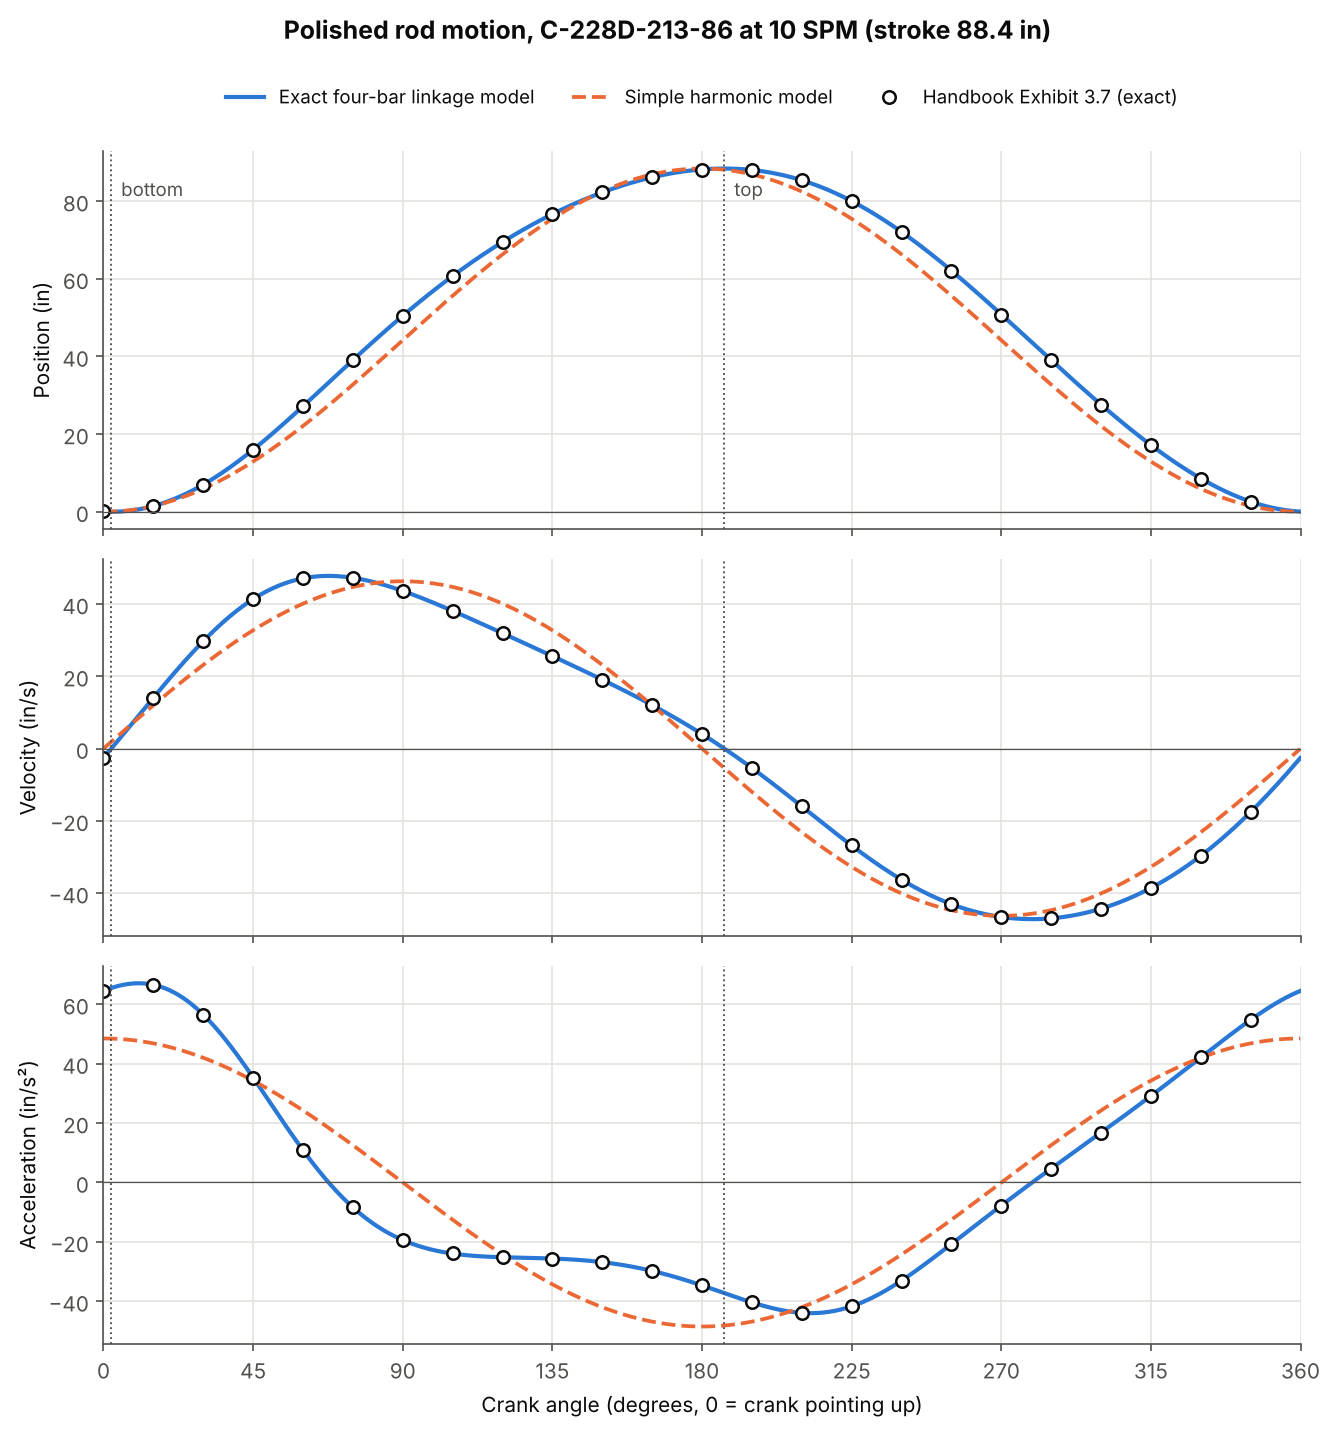

In [6]:
def plot_motion(exact, shm, handbook_table, unit_name, path):
    deg = exact["theta_deg"]
    fig, axes = plt.subplots(3, 1, figsize=(9, 9.5), sharex=True)
    panels = [("position", "Position (in)"),
              ("velocity", "Velocity (in/s)"),
              ("acceleration", "Acceleration (in/s²)")]
    hb_cols = {"position": "position_in", "velocity": "velocity_in_s",
               "acceleration": "accel_in_s2"}
    for ax, (key, label) in zip(axes, panels):
        ax.plot(deg, exact[key], color=BLUE, label="Exact four-bar linkage model")
        ax.plot(deg, shm[key], color=ORANGE, ls="--", lw=1.8, label="Simple harmonic model")
        ax.plot(handbook_table["crank_deg"], handbook_table[hb_cols[key]], "o",
                ms=6, mfc="white", mec=INK, mew=1.2, label="Handbook Exhibit 3.7 (exact)")
        for i in (exact["i_bottom"], exact["i_top"]):
            ax.axvline(deg[i], color=INK2, lw=0.9, ls=":")
        ax.axhline(0, color=INK2, lw=0.6)
        ax.set_ylabel(label)
    axes[0].text(deg[exact["i_bottom"]] + 3, exact["stroke"] * 0.92, "bottom", color=INK2, fontsize=9)
    axes[0].text(deg[exact["i_top"]] + 3, exact["stroke"] * 0.92, "top", color=INK2, fontsize=9)
    axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, 1.22), ncol=3, fontsize=9)
    axes[-1].set_xlabel("Crank angle (degrees, 0 = crank pointing up)")
    axes[-1].set_xlim(0, 360)
    axes[-1].set_xticks(range(0, 361, 45))
    fig.suptitle(f"Polished rod motion, {unit_name} at {exact['spm']:.0f} SPM "
                 f"(stroke {exact['stroke']:.1f} in)", fontweight="bold", y=1.0)
    fig.tight_layout()
    if path:
        fig.savefig(path)
    plt.show()


plot_motion(exact, shm, handbook_table(), unit["name"], OUT / "01_motion_shm_vs_exact.png")

The open circles are the handbook's exact values. They sit on our blue curve, so the exact model is right.
The simple harmonic model (dashed) underestimates the acceleration at the bottom of the stroke, which is exactly
where the rods pick up the fluid load.

## Step 3 – Rod loads

$$W_{rf} = W_r(1 - 0.128\,SpGr) \qquad F_o = 0.34\,SpGr\,d^2 L$$

Rod stretch under the fluid load uses Hooke's law with the elastic constants in Table 3.9:
stretch = $F_o \times \sum (E_r \times \text{length})$. The tubing is anchored, so the plunger stroke is $S - \text{stretch}$.

In [7]:
def rod_string_weight(rod_string, rod_table):
    """Weight of each rod taper and of the whole string in air.

    W = (length of taper, ft) x (rod weight per foot, lb/ft from Table 3.9)
    """
    tapers = []
    for taper in rod_string:
        data = rod_table[taper["size"]]
        weight = taper["length_ft"] * data["weight_lb_ft"]
        tapers.append({**taper, **data, "weight_lb": weight})
    total = sum(t["weight_lb"] for t in tapers)
    return total, tapers


def buoyant_weight(rod_weight_air_lb, liquid_spgr):
    """Buoyant weight of the rod string (review 2.8, handbook Eq. 3.13):

        W_rf = W_r * (1 - 0.128 * SpGr)

    0.128 comes from the density of water (62.4 lb/cu ft) divided by the
    density of steel (487.5 lb/cu ft).
    """
    return rod_weight_air_lb * (1.0 - 0.128 * liquid_spgr)


def fluid_load(plunger_diameter_in, pump_depth_ft, liquid_spgr=1.0):
    """Fluid load on the plunger (review 2.8):

        F_o = 0.34 * SpGr * d^2 * L

    For water (SpGr = 1) this is exactly the review formula F_o = 0.34 d^2 L.
    Where 0.34 comes from: water pressure rises 0.433 psi per foot of depth,
    and the plunger area is (pi/4) d^2, so 0.433 x 0.785 = 0.34.
    """
    return 0.34 * liquid_spgr * plunger_diameter_in**2 * pump_depth_ft


def rod_stretch(fluid_load_lb, rod_string, rod_table):
    """Stretch of the rods when they pick up the fluid load (Hooke's law).

    For each taper:  stretch = F_o x Er x length
    Er (in per lb per ft) is the elastic constant from handbook Table 3.9.
    The stretches of all tapers are added together.
    """
    total = 0.0
    for taper in rod_string:
        er = rod_table[taper["size"]]["elastic_in_lbft"]
        total += fluid_load_lb * er * taper["length_ft"]
    return total


def plunger_stroke(polished_rod_stroke_in, stretch_in):
    """Static plunger stroke. The first part of every upstroke (and of every
    downstroke) only stretches or relaxes the rods; the plunger does not move
    during that part. The tubing is anchored, so it does not stretch.

        Sp = S - stretch
    """
    return max(polished_rod_stroke_in - stretch_in, 0.0)


def pump_displacement_bpd(plunger_stroke_in, spm, plunger_diameter_in, fillage=1.0):
    """Theoretical pump displacement in barrels per day (extra output).

        PD = 0.1166 * Sp * N * d^2 * fillage

    0.1166 = (pi/4) x 1440 minutes per day / 9702 cubic inches per barrel.
    'fillage' is the fraction of the barrel that fills with liquid.
    """
    return 0.1166 * plunger_stroke_in * spm * plunger_diameter_in**2 * fillage


def estimated_peak_and_min_loads(W_r, W_rf, F_o, max_accel_in_s2, min_accel_in_s2,
                                 g_in_s2=386.09):
    """Rough estimate of how DYNAMIC loads (review 2.8) change the highest and
    lowest polished rod loads, using the handbook's simplest method
    (Eqs 3.71-3.74): the rod string is treated as one rigid mass, so the extra
    load is (rod mass) x (acceleration) = W_r x a / g.

      peak load ~ W_rf + F_o + W_r * a_max / g   (rods speeding up at the bottom)
      min load  ~ W_rf       - W_r * |a_min| / g (rods slowing down near the top)

    a / g is the handbook's "acceleration factor". With the simple harmonic
    model it becomes Mills' S*N^2/70,500. The handbook warns this is only a
    rough estimate, best suited to shallow wells.
    """
    peak = W_rf + F_o + W_r * max_accel_in_s2 / g_in_s2
    low = W_rf - W_r * abs(min_accel_in_s2) / g_in_s2
    return peak, low


In [8]:
W_r, tapers = rod_string_weight(ROD_STRING, ROD_TABLE)
W_rf = buoyant_weight(W_r, LIQUID_SPGR)
F_o = fluid_load(PLUNGER_DIAMETER_IN, PUMP_DEPTH_FT, LIQUID_SPGR)
stretch = rod_stretch(F_o, ROD_STRING, ROD_TABLE)
L = {"tapers": tapers, "W_r": W_r, "W_rf": W_rf, "F_o": F_o, "stretch": stretch,
     "upstroke_load": W_rf + F_o, "downstroke_load": W_rf}

for t in tapers:
    print(f"{t['size']:>4} in rods, {t['length_ft']:,.0f} ft : {t['weight_lb']:8,.0f} lb")
print(f"Rod weight in air W_r      : {W_r:8,.0f} lb")
print(f"Buoyant rod weight W_rf    : {W_rf:8,.0f} lb")
print(f"Fluid load on plunger F_o  : {F_o:8,.0f} lb")
print(f"Rod stretch under F_o      : {stretch:8.1f} in")

 3/4 in rods, 3,379 ft :    5,521 lb
 5/8 in rods, 1,621 ft :    1,840 lb
Rod weight in air W_r      :    7,361 lb
Buoyant rod weight W_rf    :    6,419 lb
Fluid load on plunger F_o  :   10,625 lb
Rod stretch under F_o      :     53.2 in


## Step 4 – Ideal dynamometer card

Following the review (section 2.9):
- **Upstroke:** the load climbs from $W_{rf}$ to $W_{rf}+F_o$ while the rods stretch, then stays there.
- **Downstroke:** the load drops back to $W_{rf}$ while the rods relax, then stays there.

The card is built from the motion of Step 2 and the loads of Step 3.

In [9]:
def build_card(motion, W_rf, F_o, stretch, fillage=1.0):
    """Build a dynamometer card from one crank turn of motion.

    motion   : result of motion.exact_motion()
    W_rf, F_o: buoyant rod weight and fluid load (lb)
    stretch  : rod stretch under F_o (in)
    fillage  : fraction of the pump barrel filled with liquid (0 to 1)

    Note: this is the IDEAL (static) card, so it does not depend on pumping
    speed. The effect of speed on loads is estimated separately in
    loads.estimated_peak_and_min_loads().

    Returns a dict with the surface card (position, load), the downhole pump
    card (plunger position, fluid load on the plunger) and key numbers.
    """
    S = motion["stroke"]
    Sp = plunger_stroke(S, stretch)
    empty_part = (1.0 - fillage) * Sp            # length of barrel with no liquid

    # Reorder the crank-angle data so that it starts at the bottom of the stroke
    n = len(motion["position"])
    order = np.roll(np.arange(n), -motion["i_bottom"])
    x = motion["position"][order]
    i_top = (motion["i_top"] - motion["i_bottom"]) % n
    on_upstroke = np.arange(n) < i_top

    # Fraction of the fluid load carried by the rods (0 = none, 1 = all of it)
    share = np.empty(n)
    # Upstroke: rods pick up the load over the first 'stretch' inches of travel
    share[on_upstroke] = np.clip(x[on_upstroke] / max(stretch, 1e-9), 0.0, 1.0)
    # Downstroke: the load stays on the rods while the plunger crosses the
    # empty part of the barrel, then drops over the next 'stretch' inches
    travel_down = S - x[~on_upstroke]
    share[~on_upstroke] = 1.0 - np.clip((travel_down - empty_part) / max(stretch, 1e-9), 0.0, 1.0)

    load = W_rf + F_o * share

    # Downhole pump card (static): the plunger lags the polished rod by the
    # amount the rods are stretched at that moment.
    plunger_x = x - stretch * share
    plunger_x = plunger_x - plunger_x.min()
    pump_load = F_o * share

    close = lambda a: np.append(a, a[0])          # join the loop for plotting
    return {
        "position": close(x), "load": close(load),
        "plunger_position": close(plunger_x), "pump_load": close(pump_load),
        "stroke": S, "plunger_stroke": Sp,
        "effective_plunger_stroke": fillage * Sp,
        "fillage": fillage,
        "peak_load": float(load.max()), "min_load": float(load.min()),
    }


In [10]:
card = build_card(exact, W_rf, F_o, stretch)
Sp = card["plunger_stroke"]
print(f"Upstroke load W_rf + F_o : {W_rf + F_o:8,.0f} lb")
print(f"Downstroke load W_rf     : {W_rf:8,.0f} lb")
print(f"Polished rod stroke S    : {S:8.1f} in")
print(f"Plunger stroke           : {Sp:8.1f} in  ({Sp/S*100:.0f}% of S)")
print(f"Theoretical pump output  : {pump_displacement_bpd(Sp, N, PLUNGER_DIAMETER_IN):8.0f} bbl/d")

Upstroke load W_rf + F_o :   17,044 lb
Downstroke load W_rf     :    6,419 lb
Polished rod stroke S    :     88.4 in
Plunger stroke           :     35.2 in  (40% of S)
Theoretical pump output  :      257 bbl/d


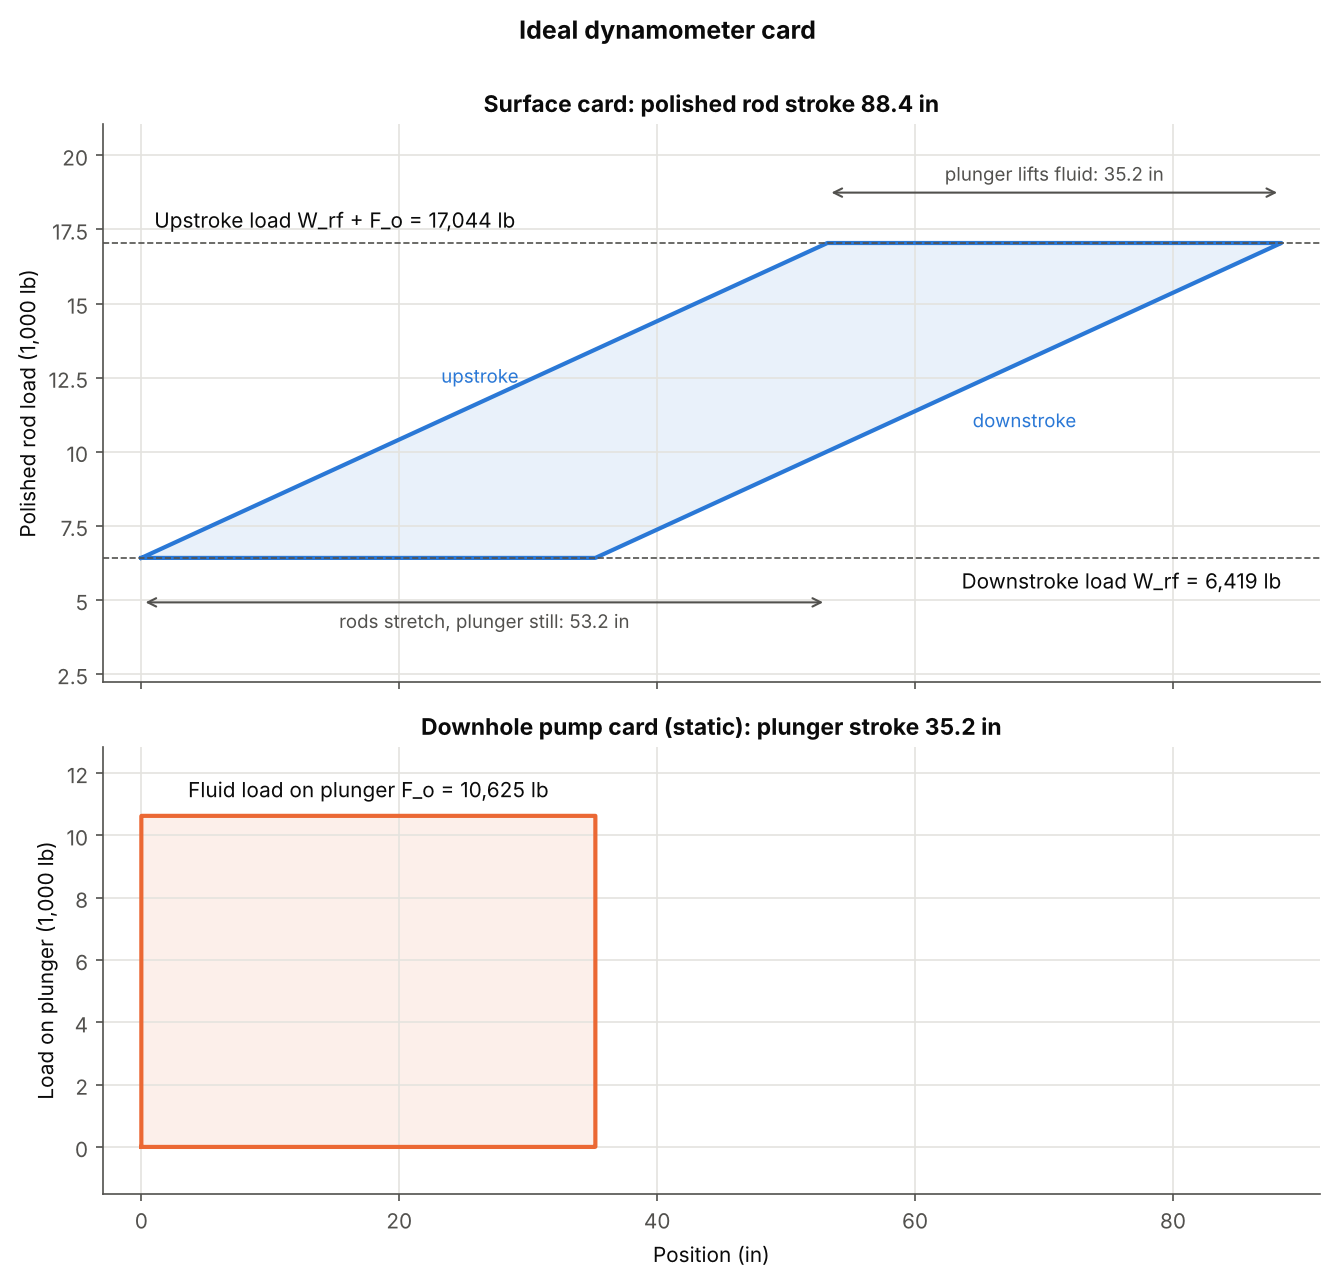

In [11]:
def plot_ideal_card(card, loads, path):
    W_rf, F_o, d = loads["W_rf"], loads["F_o"], loads["stretch"]
    S, Sp = card["stroke"], card["plunger_stroke"]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8.5), sharex=True,
                                   gridspec_kw={"height_ratios": [1.25, 1]})

    # --- surface card ---
    ax1.fill(card["position"], card["load"], color=BLUE, alpha=0.10, lw=0)
    ax1.plot(card["position"], card["load"], color=BLUE)
    top, bot = W_rf + F_o, W_rf
    for level in (top, bot):
        ax1.axhline(level, color=INK2, lw=0.8, ls="--")
    # load levels, written where the card leaves free space
    ax1.text(1, top + 350, f"Upstroke load W_rf + F_o = {top:,.0f} lb", color=INK, va="bottom")
    ax1.text(S, bot - 350, f"Downstroke load W_rf = {bot:,.0f} lb", color=INK, ha="right", va="top")
    # what happens along the stroke
    ax1.annotate("", xy=(d, bot - 1500), xytext=(0, bot - 1500),
                 arrowprops=dict(arrowstyle="<->", color=INK2, lw=1))
    ax1.text(d / 2, bot - 1750, f"rods stretch, plunger still: {d:.1f} in",
             ha="center", va="top", fontsize=9, color=INK2)
    ax1.annotate("", xy=(S, top + 1700), xytext=(d, top + 1700),
                 arrowprops=dict(arrowstyle="<->", color=INK2, lw=1))
    ax1.text((S + d) / 2, top + 1950, f"plunger lifts fluid: {Sp:.1f} in",
             ha="center", va="bottom", fontsize=9, color=INK2)
    ax1.text(d * 0.55, (top + bot) / 2 + 600, "upstroke", rotation=0, ha="right",
             fontsize=9, color=BLUE)
    ax1.text(d * 0.55 + Sp, (top + bot) / 2 - 900, "downstroke", ha="left",
             fontsize=9, color=BLUE)
    ax1.set_ylim(bot - 4200, top + 4000)
    ax1.set_ylabel("Polished rod load (1,000 lb)")
    _klb(ax1)
    ax1.set_title(f"Surface card: polished rod stroke {S:.1f} in")

    # --- downhole pump card ---
    ax2.fill(card["plunger_position"], card["pump_load"], color=ORANGE, alpha=0.10, lw=0)
    ax2.plot(card["plunger_position"], card["pump_load"], color=ORANGE)
    ax2.set_ylim(-1500, F_o + 2200)
    ax2.text(Sp / 2, F_o + 600, f"Fluid load on plunger F_o = {F_o:,.0f} lb", ha="center")
    ax2.set_ylabel("Load on plunger (1,000 lb)")
    _klb(ax2)
    ax2.set_title(f"Downhole pump card (static): plunger stroke {Sp:.1f} in")
    ax2.set_xlabel("Position (in)")
    ax2.set_xlim(-3, S + 3)
    fig.suptitle("Ideal dynamometer card", fontweight="bold", y=1.0)
    fig.tight_layout()
    if path:
        fig.savefig(path)
    plt.show()


plot_ideal_card(card, L, OUT / "02_ideal_dynamometer_card.png")

More than half of the 88 in surface stroke goes into stretching the rods, so the plunger moves much less than the
polished rod. This is problem statement point 1 in numbers. (This is the static result. In real wells, rod vibration
changes it, which needs the damped wave equation, the next stage of the project.)

## Step 5 – "What if" cases

We change one thing at a time: pumping speed, stroke length (crank hole), and how full the pump gets.
For speed, the peak and minimum loads use the handbook's rough method, which treats the rods as one rigid mass
(extra load = $W_r \times a / g$).

In [12]:
def speed_cases(unit, loads, speeds, plunger_d_in):
    """Same unit and well, different pumping speeds."""
    cases = []
    for spm in speeds:
        m = exact_motion(unit, spm)
        peak, low = estimated_peak_and_min_loads(
            loads["W_r"], loads["W_rf"], loads["F_o"],
            m["acceleration"].max(), m["acceleration"].min())
        sp = plunger_stroke(m["stroke"], loads["stretch"])
        cases.append({
            "spm": spm, "motion": m,
            "max_accel": float(m["acceleration"].max()),
            "min_accel": float(m["acceleration"].min()),
            "mills_accel": mills_peak_acceleration_ft_s2(m["stroke"], spm) * 12.0,  # in/s^2
            "peak_load": peak, "min_load": low,
            "pd": pump_displacement_bpd(sp, spm, plunger_d_in),
        })
    return cases


def stroke_cases(unit, loads, radii, spm, plunger_d_in):
    """Same unit, pitman moved to different crank holes (radius R)."""
    cases = []
    for R in radii:
        u = {**unit, "R": R}
        m = exact_motion(u, spm)
        card = build_card(m, loads["W_rf"], loads["F_o"], loads["stretch"])
        cases.append({
            "R": R, "motion": m, "card": card,
            "pd": pump_displacement_bpd(card["plunger_stroke"], spm, plunger_d_in),
        })
    return cases


def fillage_cases(motion, loads, fillages, plunger_d_in):
    """Same unit and speed, pump barrel filling to different levels."""
    cases = []
    for f in fillages:
        card = build_card(motion, loads["W_rf"], loads["F_o"], loads["stretch"], fillage=f)
        cases.append({
            "fillage": f, "card": card,
            "pd": pump_displacement_bpd(card["plunger_stroke"], motion["spm"], plunger_d_in, f),
        })
    return cases


 SPM   max accel (in/s2)   simple model   est. peak load   est. min load   output (bbl/d)
   6           24.1           17.4         17,504          6,117          154
   8           42.9           31.0         17,862          5,882          205
  10           67.0           48.5         18,322          5,580          257
  12           96.6           69.8         18,885          5,211          308
Unit load rating: 21,300 lb


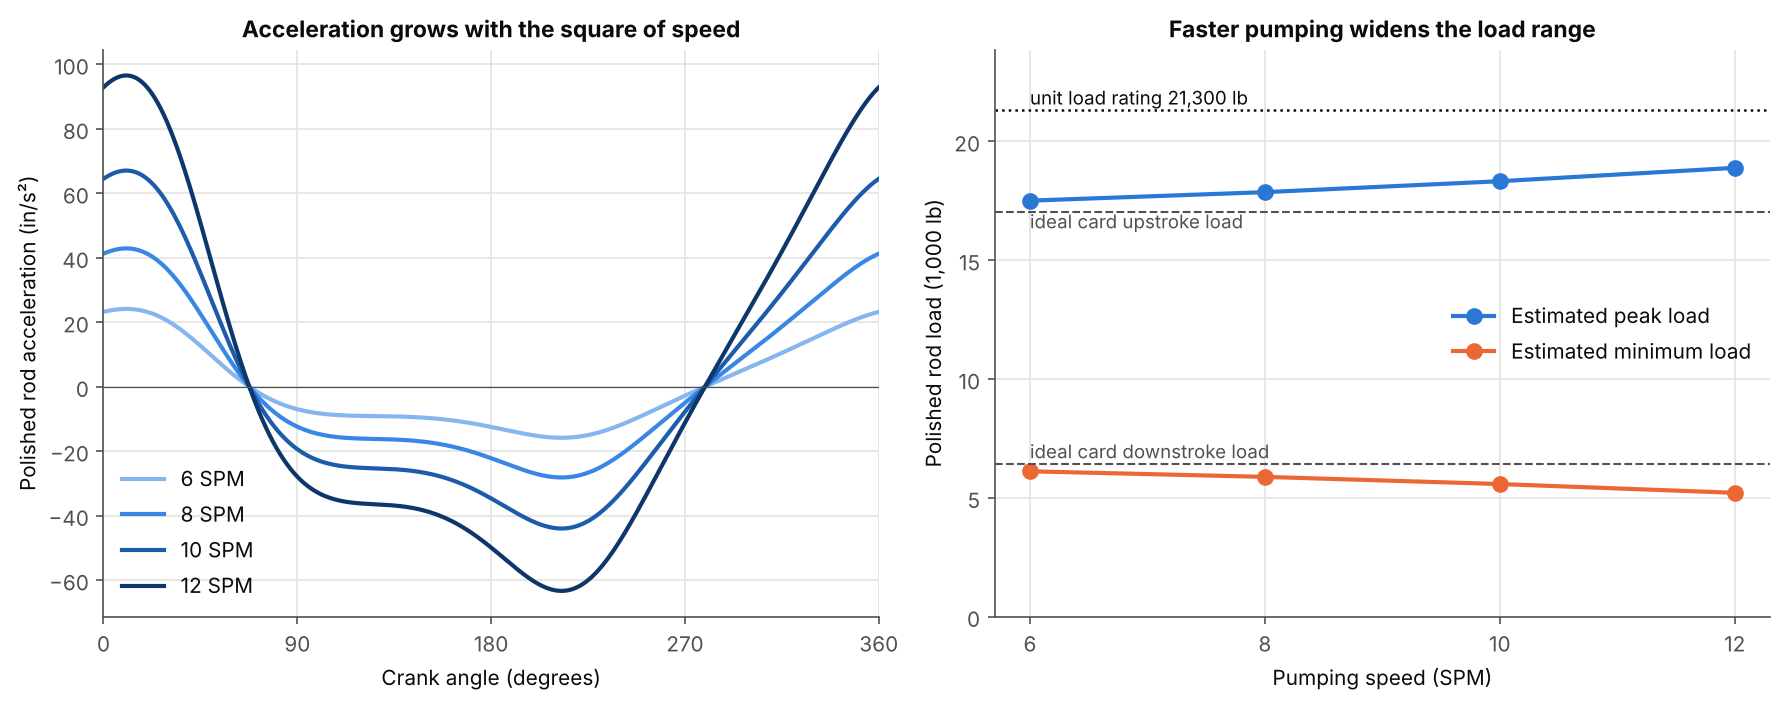

In [13]:
sp_cases = speed_cases(unit, L, WHAT_IF_SPEEDS_SPM, PLUNGER_DIAMETER_IN)
print(" SPM   max accel (in/s2)   simple model   est. peak load   est. min load   output (bbl/d)")
for c in sp_cases:
    print(f"{c['spm']:4.0f}   {c['max_accel']:12.1f}   {c['mills_accel']:12.1f}   {c['peak_load']:12,.0f}   {c['min_load']:12,.0f}   {c['pd']:10.0f}")
print(f"Unit load rating: {unit['max_load_lb']:,} lb")

def plot_speed_cases(cases, loads, unit_rating_lb, path):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
    colors = _ramp(len(cases))
    for c, col in zip(cases, colors):
        m = c["motion"]
        ax1.plot(m["theta_deg"], m["acceleration"], color=col, label=f"{c['spm']:.0f} SPM")
    ax1.axhline(0, color=INK2, lw=0.6)
    ax1.set_xlim(0, 360)
    ax1.set_xticks(range(0, 361, 90))
    ax1.set_xlabel("Crank angle (degrees)")
    ax1.set_ylabel("Polished rod acceleration (in/s²)")
    ax1.set_title("Acceleration grows with the square of speed")
    ax1.legend(loc="lower left")

    spm = [c["spm"] for c in cases]
    ax2.plot(spm, [c["peak_load"] for c in cases], "o-", color=BLUE, ms=7, label="Estimated peak load")
    ax2.plot(spm, [c["min_load"] for c in cases], "o-", color=ORANGE, ms=7, label="Estimated minimum load")
    ax2.axhline(loads["W_rf"] + loads["F_o"], color=INK2, ls="--", lw=1)
    ax2.axhline(loads["W_rf"], color=INK2, ls="--", lw=1)
    ax2.axhline(unit_rating_lb, color=INK, ls=":", lw=1.2)
    x_txt = spm[0]
    ax2.text(x_txt, loads["W_rf"] + loads["F_o"] - 700, "ideal card upstroke load", color=INK2, fontsize=9)
    ax2.text(x_txt, loads["W_rf"] + 250, "ideal card downstroke load", color=INK2, fontsize=9)
    ax2.text(x_txt, unit_rating_lb + 250, f"unit load rating {unit_rating_lb:,.0f} lb", color=INK, fontsize=9)
    ax2.set_ylim(0, unit_rating_lb * 1.12)
    ax2.set_xticks(spm)
    ax2.set_xlabel("Pumping speed (SPM)")
    ax2.set_ylabel("Polished rod load (1,000 lb)")
    _klb(ax2)
    ax2.set_title("Faster pumping widens the load range")
    ax2.legend(loc="center right")
    fig.tight_layout()
    if path:
        fig.savefig(path)
    plt.show()


plot_speed_cases(sp_cases, L, unit["max_load_lb"], OUT / "03_what_if_speed.png")

 R (in)   stroke (in)   plunger stroke (in)   output (bbl/d)
    37         88.4                 35.2            257
    32         75.7                 22.6            164
    27         63.5                 10.3             75


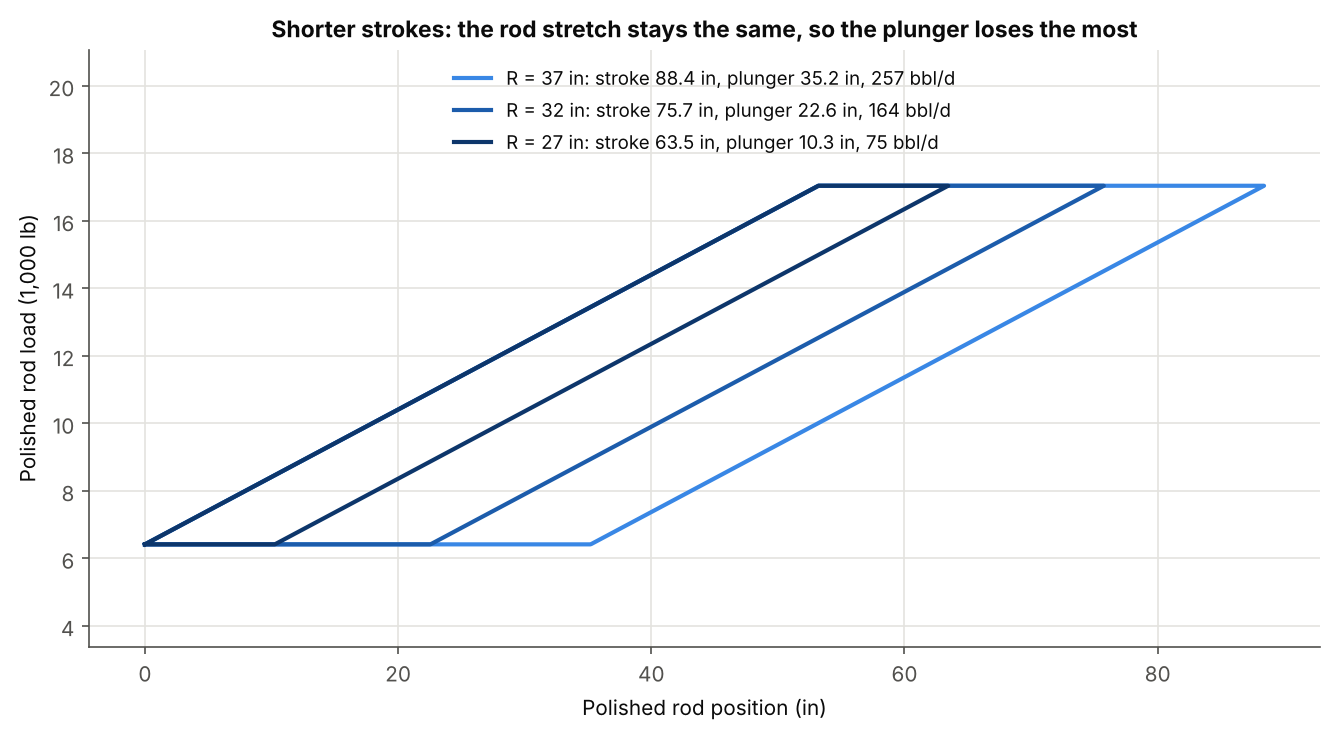

In [14]:
st_cases = stroke_cases(unit, L, WHAT_IF_CRANK_RADII_IN, N, PLUNGER_DIAMETER_IN)
print(" R (in)   stroke (in)   plunger stroke (in)   output (bbl/d)")
for c in st_cases:
    print(f"{c['R']:6.0f}   {c['card']['stroke']:10.1f}   {c['card']['plunger_stroke']:18.1f}   {c['pd']:12.0f}")

def plot_stroke_cases(cases, path):
    fig, ax = plt.subplots(figsize=(9, 5))
    colors = _ramp(len(cases))
    for c, col in zip(cases, colors):
        card = c["card"]
        ax.plot(card["position"], card["load"], color=col,
                label=f"R = {c['R']:.0f} in: stroke {card['stroke']:.1f} in, "
                      f"plunger {card['plunger_stroke']:.1f} in, {c['pd']:.0f} bbl/d")
    ax.set_xlabel("Polished rod position (in)")
    ax.set_ylabel("Polished rod load (1,000 lb)")
    _klb(ax)
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymin - 2500, ymax + 3500)
    ax.legend(loc="upper center", fontsize=9, ncol=1)
    ax.set_title("Shorter strokes: the rod stretch stays the same, so the plunger loses the most")
    fig.tight_layout()
    if path:
        fig.savefig(path)
    plt.show()


plot_stroke_cases(st_cases, OUT / "04_what_if_stroke.png")

 filling   effective plunger stroke (in)   output (bbl/d)
   100%                       35.2            257
    75%                       26.4            192
    50%                       17.6            128


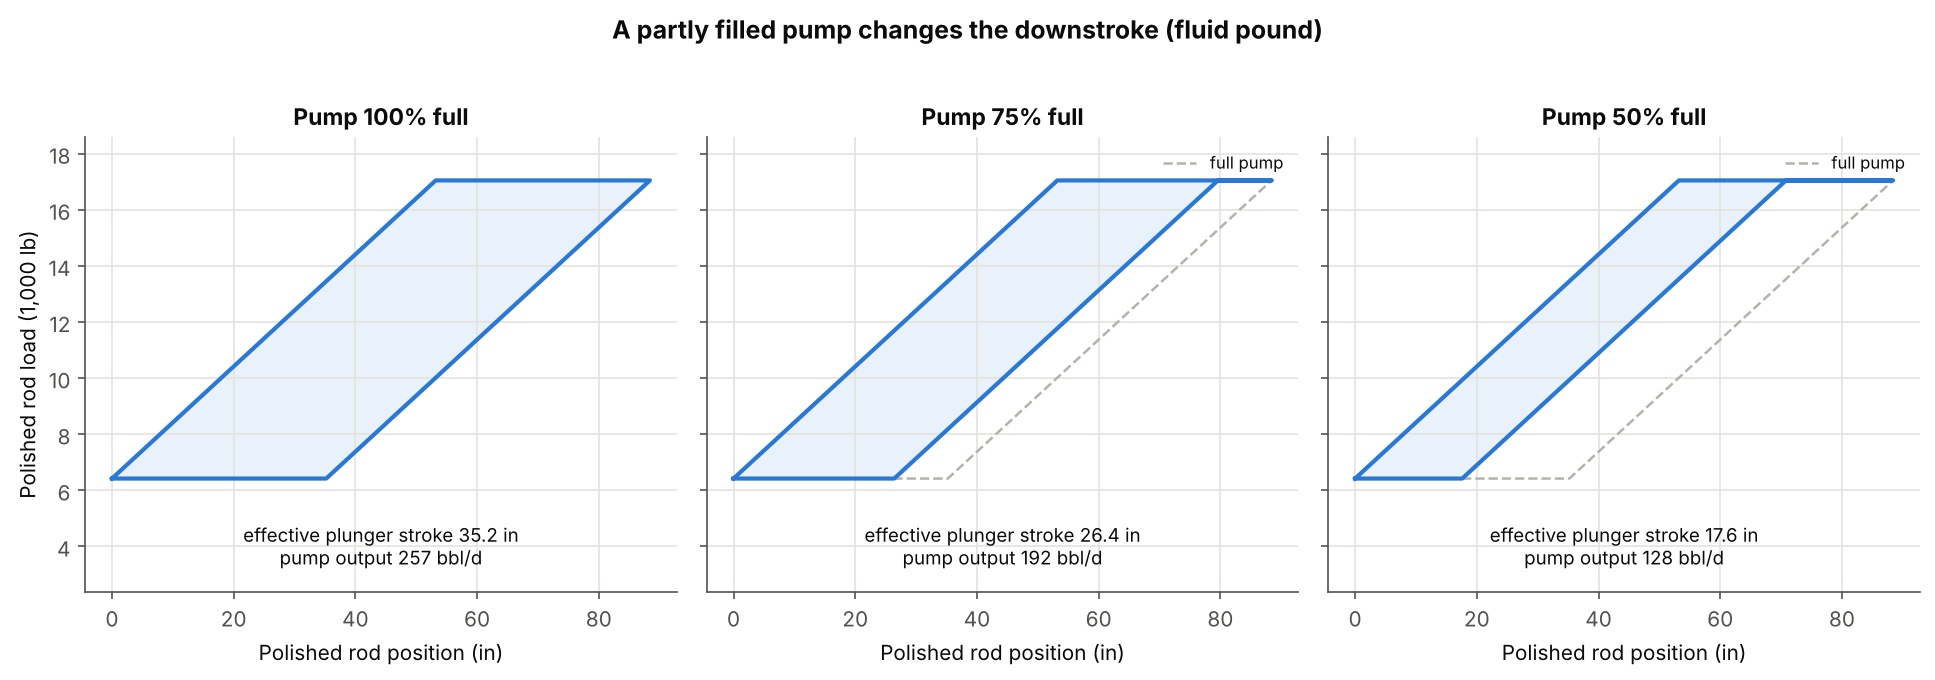

In [15]:
fi_cases = fillage_cases(exact, L, WHAT_IF_PUMP_FILLAGE, PLUNGER_DIAMETER_IN)
print(" filling   effective plunger stroke (in)   output (bbl/d)")
for c in fi_cases:
    print(f"{c['fillage']*100:6.0f}%   {c['card']['effective_plunger_stroke']:24.1f}   {c['pd']:12.0f}")

def plot_fillage_cases(cases, path):
    fig, axes = plt.subplots(1, len(cases), figsize=(13, 4.4), sharey=True)
    full = cases[0]["card"]
    for ax, c in zip(axes, cases):
        card = c["card"]
        if c is not cases[0]:
            ax.plot(full["position"], full["load"], color="#b4b2a9", lw=1.2, ls="--",
                    label="full pump")
        ax.fill(card["position"], card["load"], color=BLUE, alpha=0.10, lw=0)
        ax.plot(card["position"], card["load"], color=BLUE)
        ax.set_title(f"Pump {c['fillage']*100:.0f}% full")
        ax.text(0.5, 0.06, f"effective plunger stroke {card['effective_plunger_stroke']:.1f} in\n"
                           f"pump output {c['pd']:.0f} bbl/d",
                transform=ax.transAxes, ha="center", fontsize=9, color=INK)
        ax.set_xlabel("Polished rod position (in)")
        if c is not cases[0]:
            ax.legend(loc="upper right", fontsize=8)
    axes[0].set_ylabel("Polished rod load (1,000 lb)")
    _klb(axes[0])
    lo, hi = axes[0].get_ylim()
    axes[0].set_ylim(lo - 3500, hi + 1000)
    fig.suptitle("A partly filled pump changes the downstroke (fluid pound)",
                 fontweight="bold", y=1.02)
    fig.tight_layout()
    if path:
        fig.savefig(path)
    plt.show()


plot_fillage_cases(fi_cases, OUT / "05_what_if_pump_filling.png")

## ✓ Checks against the handbook

The review says we check our results at each step. Here the model is compared with Exhibit 3.7 (exact motion),
Example 3.10 (rod weights and fluid load) and Mills' formula.

In [16]:
def _at_angles(motion, key, angles_deg):
    """Pick model values at given crank angles (the grid is every 0.1 deg)."""
    step = 360.0 / len(motion["theta_deg"])
    idx = np.round(np.asarray(angles_deg) / step).astype(int) % len(motion["theta_deg"])
    return motion[key][idx]


def run_checks(unit, motion, shm, loads):
    """Return a list of (what was checked, our value, handbook value, passed?)."""
    results = []

    def add(name, ours, book, tol, fmt="{:.2f}"):
        results.append((name, fmt.format(ours), fmt.format(book), abs(ours - book) <= tol))

    def add_diff(name, diff, limit, fmt="{:.2f}"):
        # 'diff' is the largest gap between model and handbook; it must stay
        # within 'limit' (the rounding of the printed handbook table).
        results.append((name, fmt.format(diff), "<= " + fmt.format(limit), diff <= limit))

    # --- Step 2: motion ---------------------------------------------------
    add("Stroke length (in), handbook Exhibit 3.7", motion["stroke"], EXHIBIT_STROKE_IN, 0.2)
    add("Stroke length (in), handbook formula Eq. 3.58", motion["stroke"],
        exact_stroke_formula(unit), 0.02)
    add("Start of upstroke (deg)", motion["bottom_deg"], EXHIBIT_UP_START_DEG, 0.2, "{:.1f}")
    add("Start of downstroke (deg)", motion["top_deg"], EXHIBIT_DOWN_START_DEG, 0.2, "{:.1f}")
    add("Upstroke crank angle range (deg)", motion["upstroke_deg"], EXHIBIT_UPSTROKE_DEG, 0.2, "{:.1f}")

    ang = EXHIBIT_3_7[:, 0]
    pr_err = np.abs(_at_angles(motion, "position", ang) / motion["stroke"] - EXHIBIT_3_7[:, 1]).max()
    v_err = np.abs(_at_angles(motion, "velocity", ang) - EXHIBIT_3_7[:, 3]).max()
    a_err = np.abs(_at_angles(motion, "acceleration", ang) - EXHIBIT_3_7[:, 4]).max()
    add_diff("Largest position gap over 24 crank angles (fraction of stroke)", pr_err, 0.003, "{:.3f}")
    add_diff("Largest velocity gap over 24 crank angles (in/s)", v_err, 0.2)
    add_diff("Largest acceleration gap over 24 crank angles (in/s^2)", a_err, 0.3)

    mills = mills_peak_acceleration_ft_s2(motion["stroke"], motion["spm"]) * 12.0
    add("Simple harmonic peak acceleration (in/s^2) vs Mills' formula",
        float(shm["acceleration"].max()), mills, 0.05 * mills / 100)

    # --- Step 3: loads (handbook Example 3.10) ----------------------------
    by_size = {t["size"]: t["weight_lb"] for t in loads["tapers"]}
    if "5/8" in by_size and "3/4" in by_size:
        add("Weight of 5/8 in rods in air (lb), Example 3.10", by_size["5/8"], 1840, 1.0, "{:,.0f}")
        add("Weight of 3/4 in rods in air (lb), Example 3.10", by_size["3/4"], 5521, 1.0, "{:,.0f}")
    add("Fluid load F_o (lb), Example 3.10", loads["F_o"], 10625, 1.0, "{:,.0f}")
    return results


def format_checks(results):
    lines = [f"{'Check':<64}{'Model':>12}{'Handbook':>12}   Result", "-" * 96]
    for name, ours, book, ok in results:
        lines.append(f"{name:<64}{ours:>12}{book:>12}   {'PASS' if ok else 'FAIL'}")
    passed = sum(r[3] for r in results)
    lines.append("-" * 96)
    lines.append(f"{passed} of {len(results)} checks passed")
    return "\n".join(lines)


print(format_checks(run_checks(unit, exact, shm, L)))

Check                                                                  Model    Handbook   Result
------------------------------------------------------------------------------------------------
Stroke length (in), handbook Exhibit 3.7                               88.40       88.35   PASS
Stroke length (in), handbook formula Eq. 3.58                          88.40       88.40   PASS
Start of upstroke (deg)                                                  2.3         2.3   PASS
Start of downstroke (deg)                                              186.7       186.6   PASS
Upstroke crank angle range (deg)                                       184.4       184.3   PASS
Largest position gap over 24 crank angles (fraction of stroke)         0.001    <= 0.003   PASS
Largest velocity gap over 24 crank angles (in/s)                        0.08     <= 0.20   PASS
Largest acceleration gap over 24 crank angles (in/s^2)                  0.09     <= 0.30   PASS
Simple harmonic peak acceleration (in

## Save the motion data

Saves the motion at every 0.1° of crank angle as a CSV file (opens in Excel). It will also be the input for
the next stage of the project.

In [17]:
table = np.column_stack([exact["theta_deg"], exact["position"], exact["velocity"],
                         exact["acceleration"], exact["torque_factor"],
                         shm["position"], shm["velocity"], shm["acceleration"]])
np.savetxt(OUT / "motion_data.csv", table, delimiter=",", fmt="%.4f", comments="",
           header="crank_angle_deg,exact_position_in,exact_velocity_in_s,exact_acceleration_in_s2,"
                  "torque_factor_in,shm_position_in,shm_velocity_in_s,shm_acceleration_in_s2")
print("Saved files:", sorted(p.name for p in OUT.iterdir()))

Saved files: ['01_motion_shm_vs_exact.png', '02_ideal_dynamometer_card.png', '03_what_if_speed.png', '04_what_if_stroke.png', '05_what_if_pump_filling.png', 'motion_data.csv']


### Google Colab only: download all results
The cell below zips the `outputs` folder and downloads it. In Jupyter it does nothing, because the files are already in
the `outputs` folder next to this notebook.

In [18]:
try:
    from google.colab import files
    import shutil
    shutil.make_archive("srp_outputs", "zip", OUT)
    files.download("srp_outputs.zip")
except ImportError:
    print(f"Not running in Colab. Results are in: {OUT.resolve()}")

Not running in Colab. Results are in: /tmp/claude-0/-home-claude/07f3f693-9978-5558-b691-96fcadfb08dd/scratchpad/nbrun2/outputs
